# Панель прогресса ROADMAP-ML

Мой пульт: **Run All** (запустить всё) — и видно, где я сейчас и что изменилось с прошлого раза. Терминал не нужен.

**Где что лежит**

| Что | Где | Кто меняет |
|---|---|---|
| Эталоны методов | `src/<этап>/<подраздел>/<метод>.py` или `.../<метод>/<метод>.py` | я: код + шапка `# status:` |
| Таблица тем | `roadmap_tracker.csv` | скрипт пересобирает из `src/`; руками — только `repeated` |
| История | `progress_history.csv` | скрипт дописывает строку, когда проценты изменились |
| Картинка | `assets/progress.png` | скрипт |
| Отчёт | `README.md` | скрипт (руками не править) |
| Лог | `logs/progress.log` | скрипт, перезаписывается при каждом запуске |

**Что значат цифры**

- `status` в шапке файла: `todo` — не начинал, `in_progress` — в работе, `ready` — закрыл.
- `learned` — из статуса: todo → **0**, in_progress → **0.5**, ready → **1**.
- `repeated` — сколько раз повторил тему; 4 повторения = 100%, по нему красится кубик.
- `readme`, `experiment`, `test_create` — 1, если есть непустой README метода, ноутбук в `experiments/<slug>/`, тест `test_<slug>.py`.
- `test_run` — **1** = тест сломан (значок `!`). Проставляется сам при запуске с `pytest=True`.
- Значок `?` — в шапке нет строки `status` или статус не из словаря.

In [41]:
# Настройка: находим корень репозитория и подключаем скрипт
import importlib, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd() if (Path.cwd() / "scripts").is_dir() else Path.cwd().parent   # ноутбук лежит в notebooks/
sys.path.insert(0, str(ROOT / "scripts"))
import update_progress as up
importlib.reload(up)                                    # подхватить правки скрипта без перезапуска ядра (kernel)
pd.set_option("display.max_rows", 300, "display.max_colwidth", 80)
RUN_PYTEST = True                                       # прогнать тесты и проставить test_run автоматически
print("Корень:", ROOT)

Корень: /Users/nakhvamdis-ka/research/ROADMAP-ML


## 1. Пересборка

Обходит `src/`, пересобирает таблицу (ручное поле `repeated` сохраняется), пишет историю и лог, рисует картинку и README. Ниже — что изменилось по сравнению с таблицей до запуска.

In [42]:
csv = ROOT / "roadmap_tracker.csv"
before = pd.read_csv(csv, encoding="utf-8-sig", dtype=str, keep_default_na=False) if csv.exists() else pd.DataFrame(columns=up.COLUMNS)
df, log = up.main(ROOT, verbose=False, pytest=RUN_PYTEST)
after = pd.read_csv(csv, encoding="utf-8-sig", dtype=str, keep_default_na=False)

# что поменялось: сравниваем по path
b = before.set_index("path") if "path" in before.columns else pd.DataFrame()
a = after.set_index("path")
added, removed = sorted(set(a.index) - set(b.index)), sorted(set(b.index) - set(a.index))
changes = [{"path": p, "поле": c, "было": b.at[p, c], "стало": a.at[p, c]}
           for p in a.index.intersection(b.index) for c in a.columns
           if c in b.columns and b.at[p, c] != a.at[p, c]]
print(f"Тем: {len(after)} (было {len(before)}), новых: {len(added)}, пропало: {len(removed)}, изменённых ячеек: {len(changes)}")
for p in added:
    print("  + ", p)
for p in removed:
    print("  − ", p)
display(pd.DataFrame(changes) if changes else Markdown("_Ячейки не менялись._"))

ValueError: DataFrame index must be unique for orient='index'.

## 2. Картинка прогресса

Кубик = тема, столбец = подраздел, рамка = этап. Цвет — повторения; штриховка — сколько из четырёх задач (изучить, README, эксперимент, тест) ещё не сделано; **оранжевая рамка** — in_progress; `!` — тест сломан; `?` — нет статуса.

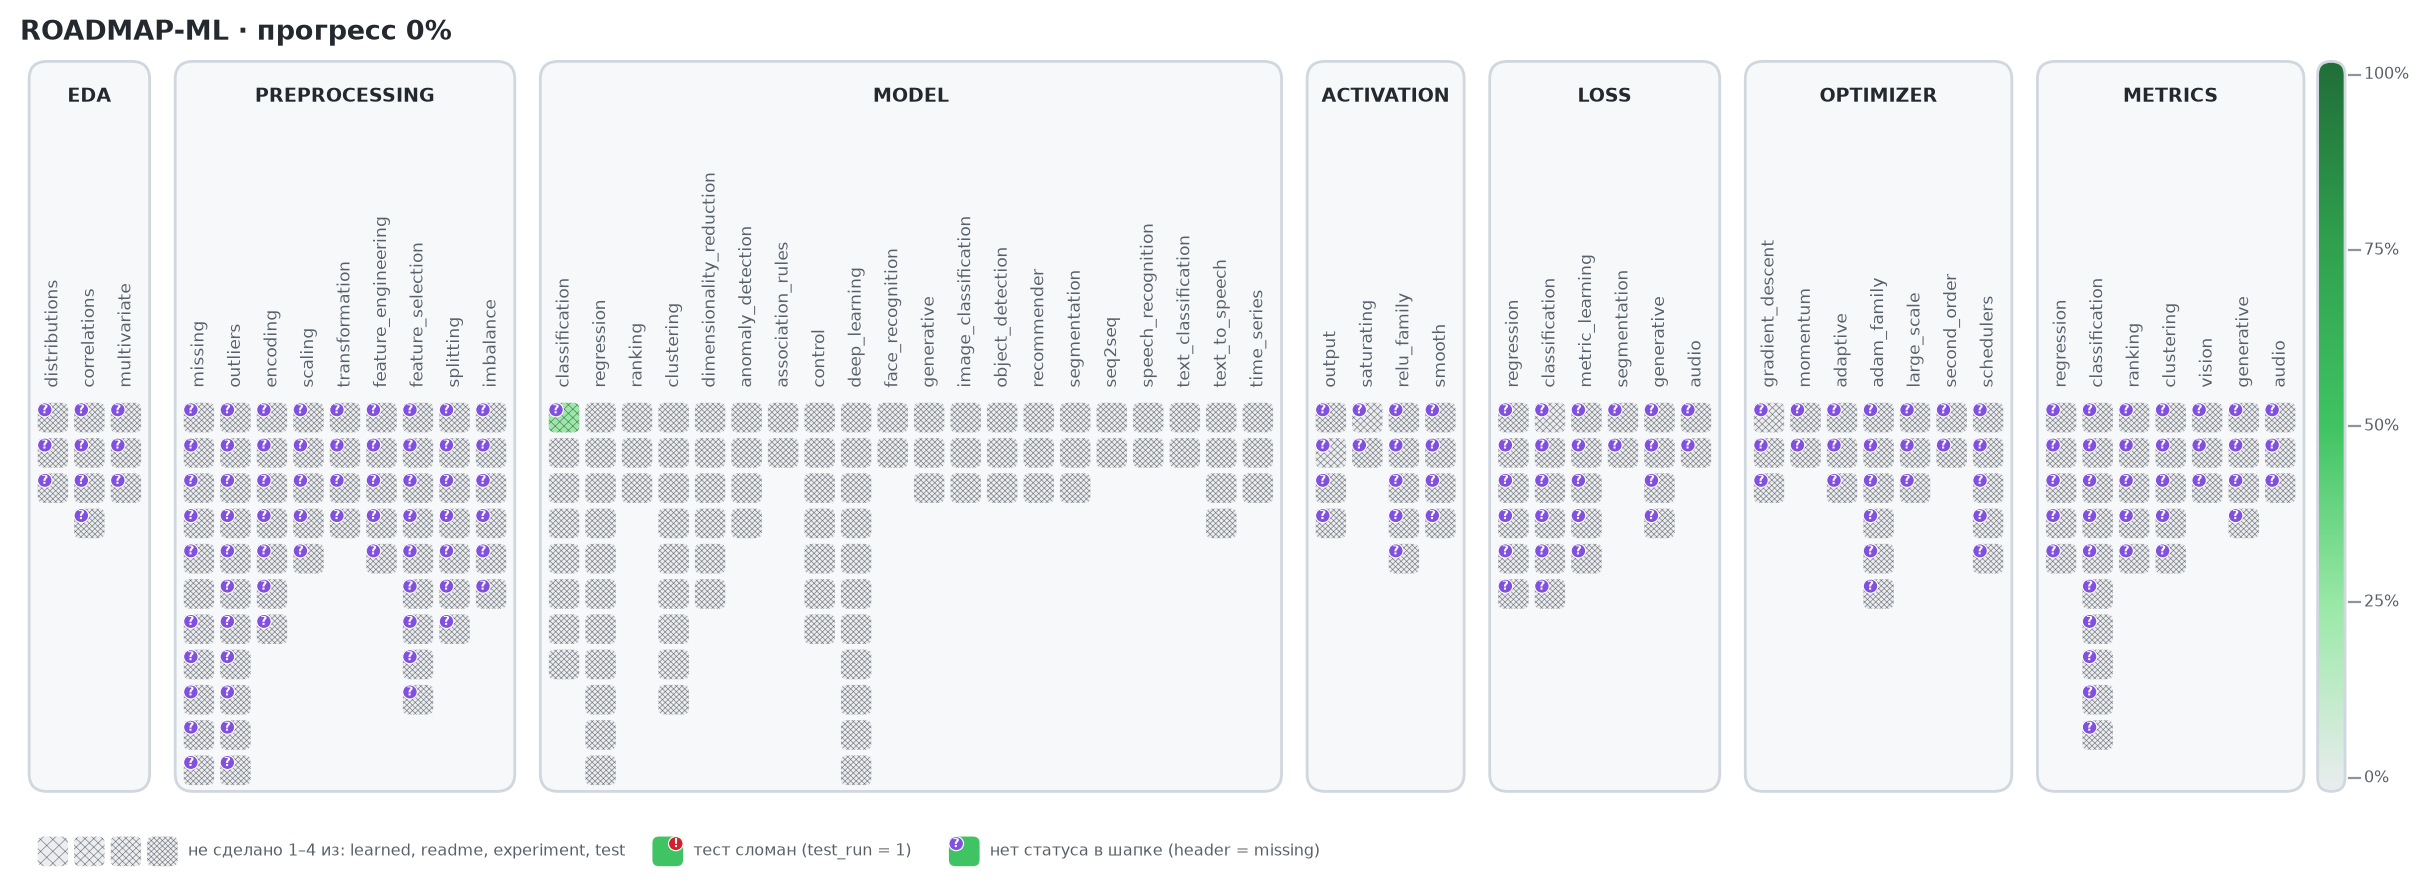

In [45]:
display(Image(filename=str(ROOT / "assets" / "progress.png")))

## 3. Проценты по этапам и история

**Готовность** — среднее `learned`. **Повторения** — `repeated` / 4, как цвет кубиков. История пишется только когда проценты меняются.

In [46]:
display(up.stage_summary(df))
hist_path = ROOT / "progress_history.csv"
if hist_path.exists():
    hist = pd.read_csv(hist_path, encoding="utf-8-sig", parse_dates=["datetime"])
    display(hist.tail(10))
    if len(hist) > 1:
        hist.set_index("datetime")[up.HISTORY_COLS[1:]].plot(figsize=(9, 3.5), marker="o", ylabel="готовность, %", grid=True)

KeyError: 'stage'

## 4. Где проблемы

In [47]:
d = up.numeric(df)
cols = ["slug", "stage", "subsection", "path"]

display(Markdown(f"**`!` Сломан тест (test_run = 1) — {int((d.test_run == 1).sum())}**"))
display(d.loc[d.test_run == 1, cols])
bad = ~d.status.isin(up.LEARNED)
display(Markdown(f"**`?` Нет или неверный статус — {int(bad.sum())}**"))
display(d.loc[bad, cols + ["status"]])

**`!` Сломан тест (test_run = 1) — 0**

KeyError: "['stage', 'subsection'] not in index"

In [48]:
# Полный лог последнего запуска (logs/progress.log)
print((ROOT / "logs" / "progress.log").read_text(encoding="utf-8"))

# update_progress 2026-10-14 19:29:16
WARN  строка «k-NN (k ближайших соседей)» (model/supervised/classification): нет файла или папки со slug «k_nn» — впишите правильный slug в таблицу (файл не создан, чтобы не плодить лишнее)
WARN  строка «Ridge / Lasso (регрессия с регуляризацией)» (model/supervised/regression): нет файла или папки со slug «ridge_lasso» — впишите правильный slug в таблицу (файл не создан, чтобы не плодить лишнее)
WARN  строка «k-NN» (model/supervised/regression): нет файла или папки со slug «k_nn» — впишите правильный slug в таблицу (файл не создан, чтобы не плодить лишнее)
WARN  строка «бустинг с ranking loss» (model/supervised/ranking): нет файла или папки со slug «бустинг_с_ranking_loss» — впишите правильный slug в таблицу (файл не создан, чтобы не плодить лишнее)
WARN  строка «K-Means» (model/unsupervised/clustering): нет файла или папки со slug «k_means» — впишите правильный slug в таблицу (файл не создан, чтобы не плодить лишнее)
WARN  строка «DBSCAN / HDBSCAN

## 5. Изучено / в работе / в планах

In [49]:
cols = ["slug", "stage", "subsection", "path", "description"]
for title, status in [("Изучено (ready)", "ready"), ("В работе (in_progress)", "in_progress")]:
    g = d[d.learned == 1] if status == "ready" else d[d.status == status]
    display(Markdown(f"**{title} — {len(g)}**"))
    display(g[cols] if len(g) else Markdown("_пусто_"))

plans = d[d.status == "todo"]
display(Markdown(f"**В планах (todo) — {len(plans)}**, по этапам:"))
display(plans.groupby("stage", sort=False).size().rename("тем").to_frame())

**Изучено (ready) — 0**

_пусто_

AttributeError: 'DataFrame' object has no attribute 'status'

In [50]:
# Список планов целиком, по этапам и подразделам
for stage in up.ORDER:
    g = plans[plans.stage == stage]
    if len(g):
        print(f"\n{stage.upper()} — {len(g)}")
        for sub, sg in g.groupby("subsection", sort=False):
            print(f"  {sub}: " + ", ".join(sg.slug))

AttributeError: 'DataFrame' object has no attribute 'stage'

## 6. Вся таблица

Руками правлю только `repeated` в `roadmap_tracker.csv`; статус — в шапке файла. Потом перезапускаю ноутбук.

In [51]:
df

,topic,chapter,step,learned,repeated,readme,experiment,test_create,test_run,slug,path,description,header
0,Logistic Regression (логистическая регрессия),model/supervised/classification,model,0.5,1,0,1,1,0,logistic_regression,src/model/supervised/classification/logistic_regression/logistic_regression.py,,missing
1,k-NN (k ближайших соседей),model/supervised/classification,model,0,0,0,0,0,0,,,,
2,Naive Bayes (наивный Байес),model/supervised/classification,model,0,0,0,0,0,0,naive_bayes,src/model/supervised/classification/naive_bayes/naive_bayes.py,,ok
3,Decision Tree (дерево решений),model/supervised/classification,model,0,0,0,0,0,0,decision_tree,src/model/supervised/classification/decision_tree/decision_tree.py,,ok
4,Random Forest (случайный лес),model/supervised/classification,model,0,0,0,0,0,0,random_forest,src/model/supervised/classification/random_forest/random_forest.py,,ok
5,"Gradient Boosting (градиентный бустинг: XGBoost, LightGBM, CatBoost)",model/supervised/classification,model,0,0,0,0,0,0,gradient_boosting,src/model/supervised/classification/gradient_boosting/gradient_boosting.py,,ok
6,SVM (метод опорных векторов),model/supervised/classification,model,0,0,0,0,0,0,svm,src/model/supervised/classification/svm/svm.py,,ok
7,Linear Regression (линейная регрессия),model/supervised/regression,model,0,0,0,0,0,0,linear_regression,src/model/supervised/regression/linear_regression/linear_regression.py,,ok
8,Ridge / Lasso (регрессия с регуляризацией),model/supervised/regression,model,0,0,0,0,0,0,,,,
9,Polynomial Regression (полиномиальная),model/supervised/regression,model,0,0,0,0,0,0,polynomial_regression,src/model/supervised/regression/polynomial_regression/polynomial_regression.py,,ok
